# d × w 实验：并行宽度 vs 串行深度（W 配平）

## 目标

问题集里并行题的**工作量** `W = 2w − 1`（链长 `[1, 2, 2, …, 2]`，共 w 条链），
串行题在 `d = W` 时深度就是 W。把两者按 **同 W** 配对，就能把「深度」和「工作量」拆开：

| W | 串行 | 并行 |
|---:|---|---|
| 1 | d=1（一条 1 步链） | w=1（一条 1 步链，退化对照） |
| 3 | d=3 | w=2（1 步 + 2 步） |
| 5 | d=5 | w=3 |
| … | … | … |
| 19 | d=19 | w=10 |

## 约束：只用 k = 1

本实验**不改变 k**，system prompt 只有基础格式约束（`####ANSWER=` 必须在最后一行）。
不加载 `constrains.jsonl` 里的任何 keyword 行约束。

## 指标（主 + 其余两个都存）

| 指标 | 定义 |
|---|---|
| **`chain_acc`（主）** | 逐链平均正确率：先算每条链对不对，再对 (题 × 链) 取平均 |
| `all_correct` | 一题的所有链**全部**答对的比例 |
| `exact_string` | 解析出的答案列表和 gold **完全一致**（个数和顺序都对） |

附带记录：`base_ok`（格式合法）、`chain_acc_by_index`（第 1 条链 vs 第 2..w 条链，前者只有 1 步、后者 2 步）、
截断率、token 数。

## 判分

- 串行：`####ANSWER=<int>`，gold 是一个整数。
- 并行：`####ANSWER=<int>,<int>,…`，按链顺序、逗号分隔；gold 是 w 个整数。
- 答案行必须是最后一行；格式不合法 → `base_ok = False`，该题所有链按错处理。
- **不惩罚草稿**：答案行之前的推理行不计入错误，只记 `n_lines`。

## 产物

| 文件 | 内容 |
|---|---|
| `d_x_w_io.jsonl` | 每条生成：`system` / `user` / `output` + 判分 |
| `d_x_w_metrics.json` | 每格汇总、逐链分位、逐题结果、曲线数据 |
| `d_x_w_curve.png` | `chain_acc` / `all_correct` 随 W 的曲线（串行 vs 并行，DA/CoT） |

## 运行环境

本 notebook 不包含任何环境检测或自动安装代码，默认在已配好 vLLM 的 GPU 机器上直接跑；
`dtype` 用 `bfloat16`（4090），T4 需改成 `float16`。


## 1. 配置

- 路径从当前目录往上找 `Experiments/`，在仓库任意子目录启动都能跑。
- 每格 40 题，两种模式共用同一批题。
- `SMOKE=True` 只跑 `W=1,3 × 5 题`，用于验证链路。
- `DTYPE="bfloat16"`：4090 用全精度；T4 请改 `"float16"`。


In [1]:
import json, os, re, sys, time, random, math
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd


def find_repo():
    here = Path.cwd()
    for p in [here] + list(here.parents):
        if (p / "Experiments" / "data_generation" / "synthesis_pointer_numeric_dataset.jsonl").exists():
            return p
    return here


REPO = find_repo()
DATA_DIR = REPO / "Experiments" / "data_generation"
OUT_DIR = REPO / "Experiments" / "final_experiments"
OUT_DIR.mkdir(parents=True, exist_ok=True)

DATASET = DATA_DIR / "synthesis_pointer_numeric_dataset.jsonl"

# ---------- 网格：W = 2w-1，串行 d = W ----------
W_LIST = [1, 3, 5, 7, 9, 11, 13, 15, 17, 19]
N_PER_CELL = 40
SEED = 20261111
MODES = ("DA", "CoT")

# ---------- 模型 ----------
HF_ID = "models/Qwen3-4B"
DTYPE = "bfloat16"          # 4090；T4 请改 "float16"
GPU_UTIL = 0.90
MAX_MODEL_LEN = 8192
MAX_NUM_SEQS = 32
TEMPERATURE, TOP_P = 0.6, 0.95
MAX_TOKENS = {"DA": 256, "CoT": 2048}

# ---------- 阶段 ----------
SMOKE = False
SMOKE_W = (1, 3)
SMOKE_N = 5

# ---------- 产物 ----------
OUT_IO = OUT_DIR / "d_x_w_io.jsonl"
OUT_METRICS = OUT_DIR / "d_x_w_metrics.json"
OUT_CURVE = OUT_DIR / "d_x_w_curve.png"

print("REPO:", REPO)
print("DATASET:", DATASET, DATASET.exists())
print("W_LIST:", W_LIST, "| w =", [(W + 1) // 2 for W in W_LIST])
print("每格 %d 题 × 2 模式 × 2 arm = %d 条" % (N_PER_CELL, len(W_LIST) * N_PER_CELL * 2 * 2))
print("dtype:", DTYPE)
print("io:", OUT_IO)


REPO: /home/ubuntu-user/Desktop/Sandoleathy/CISC7404-Project
DATASET: /home/ubuntu-user/Desktop/Sandoleathy/CISC7404-Project/Experiments/data_generation/synthesis_pointer_numeric_dataset.jsonl True
W_LIST: [1, 3, 5, 7, 9, 11, 13, 15, 17, 19] | w = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
每格 40 题 × 2 模式 × 2 arm = 1600 条
dtype: bfloat16
io: /home/ubuntu-user/Desktop/Sandoleathy/CISC7404-Project/Experiments/final_experiments/d_x_w_io.jsonl


## 2. 读题 + 抽样

- **串行**：`kind == "serial"`、`d ∈ W_LIST`。
- **并行**：`kind == "parallel"`、`w ∈ {1..10}`。
- 每格 40 题，固定种子；同一格两种模式共用。

`gold` 统一成 list：串行是 `[ans]`，并行是 `answers`（按链顺序）。


In [2]:
serial_pool = defaultdict(list)
parallel_pool = defaultdict(list)

with open(DATASET, encoding="utf-8") as f:
    for line in f:
        r = json.loads(line)
        if r["kind"] == "serial" and r["d"] in W_LIST:
            serial_pool[r["d"]].append({
                "arm": "serial",
                "W": r["d"],
                "span": r["d"],           # d
                "qid": r["qid"],
                "q": r["q"],
                "gold": [int(r["ans"])],
                "n_chains": 1,
                "chain_lengths": [r["chains"][0]["steps"]],
            })
        elif r["kind"] == "parallel" and r["w"] in range(1, 11):
            W = 2 * r["w"] - 1
            if W not in W_LIST:
                continue
            parallel_pool[r["w"]].append({
                "arm": "parallel",
                "W": W,
                "span": r["w"],           # w
                "qid": r["qid"],
                "q": r["q"],
                "gold": [int(x) for x in r["answers"]],
                "n_chains": r["w"],
                "chain_lengths": list(r["chain_lengths"]),
            })

QUESTIONS = []
for W in W_LIST:
    for arm, pool in (("serial", serial_pool[W]), ("parallel", parallel_pool[(W + 1) // 2])):
        rng = random.Random("%s|%s|W=%d" % (SEED, arm, W))
        picked = rng.sample(pool, min(N_PER_CELL, len(pool)))
        picked.sort(key=lambda x: x["qid"])
        QUESTIONS.extend(picked)
        print("W=%2d %-8s 可用 %3d -> 抽 %2d（链长 %s）" % (
            W, arm, len(pool), len(picked), picked[0]["chain_lengths"]))

assert len(QUESTIONS) == N_PER_CELL * len(W_LIST) * 2, len(QUESTIONS)
assert all(len(q["gold"]) == q["n_chains"] for q in QUESTIONS)
print("\nsanity: 每格 40 题，gold 长度 == 链数")
display(pd.DataFrame(QUESTIONS).head(3)[["arm", "W", "span", "n_chains", "qid"]])


W= 1 serial   可用 100 -> 抽 40（链长 [1]）
W= 1 parallel 可用 100 -> 抽 40（链长 [1]）
W= 3 serial   可用 100 -> 抽 40（链长 [3]）
W= 3 parallel 可用 100 -> 抽 40（链长 [1, 2]）
W= 5 serial   可用 100 -> 抽 40（链长 [5]）
W= 5 parallel 可用 100 -> 抽 40（链长 [1, 2, 2]）
W= 7 serial   可用 100 -> 抽 40（链长 [7]）
W= 7 parallel 可用 100 -> 抽 40（链长 [1, 2, 2, 2]）
W= 9 serial   可用 100 -> 抽 40（链长 [9]）
W= 9 parallel 可用 100 -> 抽 40（链长 [1, 2, 2, 2, 2]）
W=11 serial   可用 100 -> 抽 40（链长 [11]）
W=11 parallel 可用 100 -> 抽 40（链长 [1, 2, 2, 2, 2, 2]）
W=13 serial   可用 100 -> 抽 40（链长 [13]）
W=13 parallel 可用 100 -> 抽 40（链长 [1, 2, 2, 2, 2, 2, 2]）
W=15 serial   可用 100 -> 抽 40（链长 [15]）
W=15 parallel 可用 100 -> 抽 40（链长 [1, 2, 2, 2, 2, 2, 2, 2]）
W=17 serial   可用 100 -> 抽 40（链长 [17]）
W=17 parallel 可用 100 -> 抽 40（链长 [1, 2, 2, 2, 2, 2, 2, 2, 2]）
W=19 serial   可用 100 -> 抽 40（链长 [19]）
W=19 parallel 可用 100 -> 抽 40（链长 [1, 2, 2, 2, 2, 2, 2, 2, 2, 2]）

sanity: 每格 40 题，gold 长度 == 链数


,arm,W,span,n_chains,qid
0,serial,1,1,1,02f272390fe7725cfe391cfec511582ce2b8e11512dc5d...
1,serial,1,1,1,0a79f11279c231cbd60e27fe503e940a39b835ea2e813e...
2,serial,1,1,1,19f5e7cc6b41a2f3a582dd629efabfa5faf0bbdb508f7a...


## 3. Prompt（k = 1）

两套基础规则：串行答一个整数，并行答一组逗号分隔的整数。DA / CoT 的前导语也按单链 / 多链分开写，
其余措辞与 `prompts.md` 一致（禁止重复规则、禁止写没要求的行、答案行必须最后）。


In [3]:
BASE_RULE_SERIAL = (
    "Output format. Your response must contain only the final answer line. The answer line is always the "
    "very last line of the response: ####ANSWER= followed by the final index as an integer, and nothing may "
    "be written after it. Do not repeat or restate these rules.")

BASE_RULE_PARALLEL = (
    "Output format. Your response must contain only the final answer line. The answer line is always the "
    "very last line of the response: ####ANSWER= followed by the final indices in chain order, separated by "
    "commas, and nothing may be written after it. Do not repeat or restate these rules.")

DA_PREAMBLE = ("Answer with the final answer only: no calculations, no pointer steps, no intermediate "
               "values, no explanation and no comment. Write only the lines that the rules below require, "
               "plus the final answer line. Any other text makes the response invalid.\n")

COT_PREAMBLE_SERIAL = ("Solve the problem step by step. Before the final answer line, explicitly write the "
                       "index reached after each pointer step, one per line. The keyword lines required by "
                       "the rules below must come after those steps and before the final answer line.\n")

COT_PREAMBLE_PARALLEL = ("Solve the problem step by step. The chains are independent; handle them one by "
                         "one, in chain order. Before the final answer line, explicitly write the index "
                         "reached after each pointer step, chain by chain. The final answer line must "
                         "contain all final indices in chain order, separated by commas.\n")


def build_system(mode, arm):
    if arm == "serial":
        base = BASE_RULE_SERIAL
        pre = DA_PREAMBLE if mode == "DA" else COT_PREAMBLE_SERIAL
    else:
        base = BASE_RULE_PARALLEL
        pre = DA_PREAMBLE if mode == "DA" else COT_PREAMBLE_PARALLEL
    return pre + "Rules:\nR1. " + base


def build_messages(mode, q):
    return [
        {"role": "system", "content": build_system(mode, q["arm"])},
        {"role": "user", "content": q["q"]},
    ]


def make_jobs(questions, modes, stage):
    jobs = []
    for mode in modes:
        for q in questions:
            jobs.append({
                "id": "%s|%s|%s|W%d|%s" % (stage, mode, q["arm"], q["W"], q["qid"]),
                "stage": stage,
                "mode": mode,
                "arm": q["arm"],
                "W": q["W"],
                "span": q["span"],
                "qid": q["qid"],
                "gold": list(q["gold"]),
                "n_chains": q["n_chains"],
                "chain_lengths": list(q["chain_lengths"]),
                "messages": build_messages(mode, q),
            })
    return jobs


_jobs = make_jobs(QUESTIONS[:2], MODES, "selftest")
assert len(_jobs) == 2 * 2
print("示例（parallel / CoT）:\n" + "-" * 90)
_p = [j for j in _jobs if j["arm"] == "parallel" and j["mode"] == "CoT"]
print((_p or _jobs)[0]["messages"][0]["content"])


示例（parallel / CoT）:
------------------------------------------------------------------------------------------
Answer with the final answer only: no calculations, no pointer steps, no intermediate values, no explanation and no comment. Write only the lines that the rules below require, plus the final answer line. Any other text makes the response invalid.
Rules:
R1. Output format. Your response must contain only the final answer line. The answer line is always the very last line of the response: ####ANSWER= followed by the final index as an integer, and nothing may be written after it. Do not repeat or restate these rules.


## 4. 加载 vLLM（Qwen3-4B，bf16）

`Qwen3-4B-Instruct-2507` 是非 thinking 模型，**不要**传 `chat_template_kwargs={"enable_thinking": ...}`。
采样参数沿用项目统一值：`temperature=0.6`、`top_p=0.95`。


In [4]:
import torch
from vllm import LLM, SamplingParams

if not torch.cuda.is_available():
    raise RuntimeError("没有 CUDA。请在 GPU 机器上执行这一格。")

cap = torch.cuda.get_device_capability(0)
mem_gib = torch.cuda.get_device_properties(0).total_memory / 2**30
if DTYPE == "bfloat16" and cap[0] < 8:
    raise RuntimeError("这张卡不支持 bf16（capability %s），请把 DTYPE 改成 'float16'。" % (cap,))

model_path = '../../models/Qwen3-4B'
llm = LLM(
    model=model_path,
    dtype=DTYPE,
    gpu_memory_utilization=GPU_UTIL,
    max_model_len=MAX_MODEL_LEN,
    max_num_seqs=MAX_NUM_SEQS,
)

CHAT_KW = {
    "chat_template_kwargs":{
        "enable_thinking": False
    }
}   # 非 thinking 模型
SP = {m: SamplingParams(temperature=TEMPERATURE, top_p=TOP_P, max_tokens=MAX_TOKENS[m]) for m in MODES}
print("GPU: %.1f GiB, capability %s | torch %s cuda %s" % (mem_gib, cap, torch.__version__, torch.version.cuda))


W1111 16:52:30.499000 30363 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1111 16:52:30.500000 30363 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1111 16:52:30.500000 30363 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


(MainProcess pid=30363) INFO 11-11 16:52:33 [startup.py:96] non-default args: {'dtype': 'bfloat16', 'max_model_len': 8192, 'gpu_memory_utilization': 0.9, 'max_num_seqs': 32, 'disable_log_stats': True, 'model': '../../models/Qwen3-4B'}
(MainProcess pid=30363) INFO 11-11 16:52:33 [model.py:744] Resolved architecture: Qwen3ForCausalLM
(MainProcess pid=30363) INFO 11-11 16:52:33 [model.py:2170] Using max model len 8192
(MainProcess pid=30363) INFO 11-11 16:52:33 [scheduler.py:310] Chunked prefill is enabled with max_num_batched_tokens=8192.
(MainProcess pid=30363) INFO 11-11 16:52:33 [kernel.py:480] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(MainProcess pid=30363) WARNING 11-11 16:52:34 [system_utils.py:154] We must use the `spawn` multiprocessing start method. Overriding VLLM_WORKER_MULTIPROC_METHOD to 'spawn'. See https://docs.vllm.ai/en/latest/usage/troubleshootin

W1111 16:52:35.876000 30490 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1111 16:52:35.876000 30490 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1111 16:52:35.876000 30490 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


(EngineCore pid=30490) INFO 11-11 16:52:38 [core.py:139] Initializing a V1 LLM engine (v0.33.0) with config: model='../../models/Qwen3-4B', speculative_config=None, tokenizer='../../models/Qwen3-4B', skip_tokenizer_init=False, tokenizer_mode=auto, revision=None, tokenizer_revision=None, trust_remote_code=False, dtype=torch.bfloat16, max_seq_len=8192, download_dir=None, load_format=auto, tensor_parallel_size=1, pipeline_parallel_size=1, data_parallel_size=1, decode_context_parallel_size=1, dcp_comm_backend=ag_rs, disable_custom_all_reduce=False, quantization=None, quantization_config=None, enforce_eager=False, aux_output_config=AuxOutputConfig(enable_return_routed_experts=False, max_bytes=None), kv_cache_dtype=auto, device_config=cuda, structured_outputs_config=StructuredOutputsConfig(backend='auto', disable_any_whitespace=False, disable_additional_properties=False, reasoning_parser='', reasoning_parser_plugin='', enable_in_reasoning=False), observability_config=ObservabilityConfig(show

Loading safetensors checkpoint shards:   0% Completed | 0/3 [00:00<?, ?it/s]
Loading safetensors checkpoint shards:  33% Completed | 1/3 [00:00<00:00,  3.04it/s]
Loading safetensors checkpoint shards:  67% Completed | 2/3 [00:00<00:00,  3.07it/s]
Loading safetensors checkpoint shards: 100% Completed | 3/3 [00:00<00:00,  4.54it/s]



(EngineCore pid=30490) INFO 11-11 16:52:40 [default_loader.py:506] Loading weights took 0.66 seconds
(EngineCore pid=30490) INFO 11-11 16:52:42 [model_runner.py:428] Model loading took 7.56 GiB memory and 2.426981 seconds
(EngineCore pid=30490) INFO 11-11 16:52:42 [topk_topp_sampler.py:149] Using FlashInfer for top-p & top-k sampling.
(EngineCore pid=30490) INFO 11-11 16:52:42 [torch_utils.py:281] Reducing Torch threads from 16 to 1 for serving. Set OMP_NUM_THREADS in the external environment to override.
(EngineCore pid=30490) INFO 11-11 16:52:42 [utils.py:381] Using LBNHC KV cache layout.
(EngineCore pid=30490) INFO 11-11 16:52:42 [caching.py:342] reconstructed serializable fn from standalone compile artifacts. num_artifacts=3 num_submods=37
(EngineCore pid=30490) INFO 11-11 16:52:42 [decorators.py:326] [backbone] Directly load AOT compilation from path /home/ubuntu-user/.cache/vllm/torch_compile_cache/torch_aot_compile/a84315507f0c9ea1e07d611536e06364b3b2d8b8b25b92ab9981c71502555b7b

Capturing CUDA graphs (FULL): 100%|██████████| 2/2 [00:00<00:00, 53.64it/s]


(EngineCore pid=30490) INFO 11-11 16:52:44 [model_runner.py:1163] Graph capturing finished in 1 secs, took 0.12 GiB
(EngineCore pid=30490) INFO 11-11 16:52:45 [gpu_worker.py:772] Available KV cache memory: 12.84 GiB
(EngineCore pid=30490) INFO 11-11 16:52:45 [gpu_worker.py:787] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.9000 is equivalent to --gpu-memory-utilization=0.8946 without CUDA graph memory profiling. To maintain the same effective KV cache size as before, increase --gpu-memory-utilization to 0.9054. To disable, set VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=0.
(EngineCore pid=30490) INFO 11-11 16:52:45 [kv_cache_utils.py:1147] GPU KV cache size: 93,520 tokens, Maximum concurrency for 8,192 tokens per request: 11.42x
(EngineCore pid=30490) INFO 11-11 16:52:45 [kernel_warmup.py:179] JIT kernel warmup starting.
(EngineCore pid=30490) INFO 11-11 16:52:45 [kernel_warmup.py:192] JIT kernel warmup finished in 0.00s.


Capturing CUDA graphs (FULL): 100%|██████████| 7/7 [00:00<00:00, 59.98it/s]


(EngineCore pid=30490) INFO 11-11 16:52:46 [model_runner.py:1163] Graph capturing finished in 1 secs, took 0.07 GiB
(EngineCore pid=30490) INFO 11-11 16:52:46 [gpu_worker.py:1003] CUDA graph pool memory: 0.07 GiB (actual), 0.13 GiB (estimated), difference: 0.06 GiB (85.9%).
(EngineCore pid=30490) INFO 11-11 16:52:46 [gpu_worker.py:1066] Free memory on device (22.41/23.51 GiB) on startup. Desired GPU memory utilization is (0.9, 21.16 GiB). Actual usage is 7.6 GiB for consumed memory (weights + non-torch), 0.71 GiB for peak activation, and 0.07 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=13560117248` (12.63 GiB) to fit into requested memory, or `--kv-cache-memory=14909175808` (13.89 GiB) to fully utilize gpu memory. Current kv cache memory in use is 12.84 GiB.
(EngineCore pid=30490) INFO 11-11 16:52:46 [jit_monitor.py:84] Kernel JIT monitor activated; monitored JIT compilations during inference will use mode=warn.
(EngineCore pid=30490) INFO 11

## 5. 生成与判分

答案行解析：`####ANSWER=` 之后按逗号切成整数列表。
- 串行：列表长度必须 1。
- 并行：列表长度必须 == 链数；长度不对或解析失败 → `base_ok = False`，该题全部链计错。

每条记录同时存 `chain_ok`（逐链对错）、`n_correct`、`chain_acc`、`all_correct`、`exact_string`。


In [5]:
MARK = "####ANSWER="


def load_done(path):
    if not path.exists():
        return set()
    with open(path, encoding="utf-8") as f:
        return {json.loads(l)["id"] for l in f if l.strip()}


def run_jobs(jobs, path=OUT_IO):
    done = load_done(path)
    todo = [j for j in jobs if j["id"] not in done]
    print("总计 %s，已完成 %s，待跑 %s" % (len(jobs), len(jobs) - len(todo), len(todo)))
    for mode in MODES:
        part = [j for j in todo if j["mode"] == mode]
        batch = 64 if mode == "DA" else 32
        for s in range(0, len(part), batch):
            chunk = part[s:s + batch]
            t0 = time.time()
            outs = llm.chat([j["messages"] for j in chunk], SP[mode], use_tqdm=False, **CHAT_KW)
            dt = time.time() - t0
            with open(path, "a", encoding="utf-8") as f:
                for j, o in zip(chunk, outs):
                    c = o.outputs[0]
                    rec = dict(j)
                    rec.pop("messages", None)
                    rec.update(
                        system=j["messages"][0]["content"],
                        user=j["messages"][1]["content"],
                        output=c.text,
                        prompt_tokens=len(o.prompt_token_ids),
                        n_tokens=len(c.token_ids),
                        finish_reason=c.finish_reason,
                        trunc=(c.finish_reason == "length"),
                        batch_sec=round(dt, 2),
                    )
                    f.write(json.dumps(rec, ensure_ascii=False) + "\n")
            print("[%s] %s/%s  batch %.1fs" % (mode, s + len(chunk), len(part), dt))


def parse_answer(text, n_expected):
    """返回 (整数列表 或 None, 状态说明)。"""
    lines = [l.strip() for l in str(text).splitlines() if l.strip()]
    marks = [i for i, l in enumerate(lines) if l.startswith(MARK)]
    if len(marks) == 0:
        return None, "no_marker"
    if len(marks) > 1:
        return None, "multi_marker"
    i = marks[0]
    if i != len(lines) - 1:
        return None, "not_last"
    raw = lines[i][len(MARK):].strip()
    parts = [p.strip() for p in raw.split(",")]
    if not parts or not all(re.fullmatch(r"-?\d+", p) for p in parts):
        return None, "not_int_list"
    if len(parts) != n_expected:
        return None, "wrong_count_%d_of_%d" % (len(parts), n_expected)
    return [int(p) for p in parts], "ok"


def score_row(rec):
    text = rec["output"]
    gold = list(rec["gold"])
    pred, why = parse_answer(text, len(gold))
    base_ok = (why == "ok")

    if base_ok:
        chain_ok = [p == g for p, g in zip(pred, gold)]
    else:
        chain_ok = [False] * len(gold)

    n_correct = int(sum(chain_ok))
    n = len(gold)
    return {
        "pred": pred,
        "answer_reason": why,
        "base_ok": bool(base_ok),
        "chain_ok": chain_ok,
        "n_correct": n_correct,
        "n_chains": n,
        "chain_acc": (n_correct / n) if n else float("nan"),
        "all_correct": bool(n > 0 and n_correct == n),
        "exact_string": bool(base_ok and pred == gold),
        "n_lines": len([l for l in str(text).splitlines() if l.strip()]),
        "n_tokens": rec["n_tokens"],
        "trunc": bool(rec["trunc"]),
    }


## 6. 冒烟（可选）

`SMOKE=True` 时只跑 `W=1,3`（串行 + 并行）× 5 题 × 2 模式 = 40 条，用来确认
① 题干能进模型、② 并列答案能按逗号解析、③ 链数校验能跑通。跑完改回 `SMOKE=False` 再跑全量。


In [7]:
smoke_qs = [q for q in QUESTIONS if q["W"] in SMOKE_W]
smoke_qs = smoke_qs[: SMOKE_N * len(SMOKE_W) * 2]
smoke_jobs = make_jobs(smoke_qs, MODES, "smoke")
print("smoke questions:", len(smoke_qs), "| jobs:", len(smoke_jobs))
run_jobs(smoke_jobs)

sm = []
if OUT_IO.exists():
    with open(OUT_IO, encoding="utf-8") as f:
        for line in f:
            if line.strip():
                rr = json.loads(line)
                if rr["stage"] == "smoke":
                    sm.append(rr)
if sm:
    sdf = pd.DataFrame([{**r, **score_row(r)} for r in sm])
    display(sdf.groupby(["arm", "W", "mode"]).agg(
        n=("qid", "size"), chain_acc=("chain_acc", "mean"), all_correct=("all_correct", "mean"),
        exact=("exact_string", "mean"), base=("base_ok", "mean"), trunc=("trunc", "mean"),
    ).round(3))
    bad = sdf[~sdf["base_ok"]]
    if len(bad):
        print("\n解析失败原因:", bad["answer_reason"].value_counts().to_dict())
        for _, r in bad.head(3).iterrows():
            print("-" * 60, r["arm"], r["W"], r["mode"])
            print(repr(r["output"])[:300])


smoke questions: 20 | jobs: 40
总计 40，已完成 0，待跑 40
[DA] 20/20  batch 0.4s
[CoT] 20/20  batch 1.7s


n  chain_acc  all_correct  exact  base  trunc
arm    W mode                                                
serial 1 CoT   20       0.65         0.65   0.65   1.0    0.0
         DA    20       0.50         0.50   0.50   1.0    0.0

## 7. 全量运行

`W ∈ {1,3,…,19}` × 2 arm（串行 d=W，并行 w=(W+1)/2）× 40 题 × 2 模式 = **1600 条**。
可中断；重跑按 `id` 跳过已完成的。


In [8]:
jobs = make_jobs(QUESTIONS, MODES, "full")
print("jobs:", len(jobs))
run_jobs(jobs)

rows = [json.loads(l) for l in open(OUT_IO, encoding="utf-8") if l.strip()]
rows = [r for r in rows if r["stage"] == "full"]
print("full 已完成:", len(rows))
assert len(rows) == len(jobs), "还没跑完，重跑本格续跑"


jobs: 1600
总计 1600，已完成 0，待跑 1600
[DA] 64/800  batch 3.6s
[DA] 128/800  batch 3.9s
[DA] 192/800  batch 1.4s
[DA] 256/800  batch 1.6s
[DA] 320/800  batch 1.8s
[DA] 384/800  batch 1.8s
[DA] 448/800  batch 2.0s
[DA] 512/800  batch 1.9s
[DA] 576/800  batch 4.2s
[DA] 640/800  batch 2.6s
[DA] 704/800  batch 2.3s
[DA] 768/800  batch 2.5s


[rank0]:[W1111 16:54:00.595110351 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 318767104 bytes (free: 331874304, total: 25241190400).


[DA] 800/800  batch 1.9s
[CoT] 32/800  batch 23.1s
[CoT] 64/800  batch 21.5s
[CoT] 96/800  batch 1.9s
[CoT] 128/800  batch 2.6s
[CoT] 160/800  batch 2.9s
[CoT] 192/800  batch 2.8s
[CoT] 224/800  batch 3.7s
[CoT] 256/800  batch 5.0s
[CoT] 288/800  batch 5.1s
[CoT] 320/800  batch 5.1s
[CoT] 352/800  batch 5.3s
[CoT] 384/800  batch 6.0s
[CoT] 416/800  batch 5.9s
[CoT] 448/800  batch 6.1s
[CoT] 480/800  batch 6.9s
[CoT] 512/800  batch 4.8s
[CoT] 544/800  batch 7.5s
[CoT] 576/800  batch 7.3s
[CoT] 608/800  batch 8.6s
[CoT] 640/800  batch 8.5s
[CoT] 672/800  batch 6.1s
[CoT] 704/800  batch 9.0s
[CoT] 736/800  batch 8.9s
[CoT] 768/800  batch 9.8s
[CoT] 800/800  batch 11.3s
full 已完成: 1600


## 8. 汇总、metrics.json 与曲线

- **每格**（arm, W, mode）：`chain_acc`（主）、`all_correct`、`exact_string`、`base_ok`、截断率。
- **逐链位置**：并行题里第 1 条链只有 1 步、第 2..w 条各有 2 步，分开统计 `chain_acc_by_index`。
- 曲线：x = W，左图 `chain_acc`、右图 `all_correct`，每张图 4 条线（串行/并行 × DA/CoT）。


链数正确率（主指标 chain_acc）:


arm  parallel        serial      
mode      CoT     DA    CoT    DA
W                                
1       0.975  0.425  0.625  0.45
3       0.925  0.412  0.825  0.05
5       0.925  0.242  0.625  0.00
7       0.806  0.188  0.475  0.10
9       0.790  0.145  0.350  0.05
11      0.450  0.108  0.475  0.00
13      0.346  0.121  0.325  0.00
15      0.469  0.088  0.275  0.00
17      0.403  0.103  0.400  0.00
19      0.418  0.098  0.350  0.00


all_correct:


arm  parallel        serial      
mode      CoT     DA    CoT    DA
W                                
1       0.975  0.425  0.625  0.45
3       0.850  0.075  0.825  0.05
5       0.850  0.025  0.625  0.00
7       0.700  0.000  0.475  0.10
9       0.600  0.000  0.350  0.05
11      0.175  0.000  0.475  0.00
13      0.100  0.000  0.325  0.00
15      0.175  0.000  0.275  0.00
17      0.150  0.000  0.400  0.00
19      0.225  0.000  0.350  0.00


written: /home/ubuntu-user/Desktop/Sandoleathy/CISC7404-Project/Experiments/final_experiments/d_x_w_metrics.json | rows: 1600


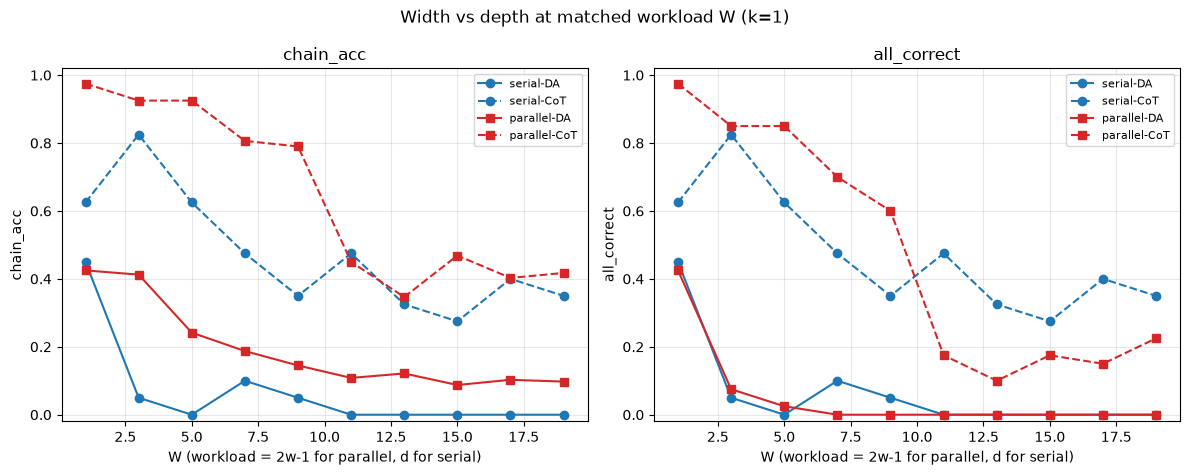

written: /home/ubuntu-user/Desktop/Sandoleathy/CISC7404-Project/Experiments/final_experiments/d_x_w_curve.png


In [9]:
rows = [json.loads(l) for l in open(OUT_IO, encoding="utf-8") if l.strip()]
rows = [r for r in rows if r["stage"] == "full"]

scored = []
for r in rows:
    s = score_row(r)
    rec = {k: r[k] for k in ("id", "stage", "mode", "arm", "W", "span", "qid", "gold",
                             "n_chains", "chain_lengths", "finish_reason", "prompt_tokens")}
    rec.update(s)
    rec["output"] = r["output"]
    scored.append(rec)

df = pd.DataFrame(scored)

# ---- 每格汇总 ----
cells = []
for (arm, W, mode), g in df.groupby(["arm", "W", "mode"]):
    by_idx = defaultdict(list)
    for chain_ok in g["chain_ok"]:
        for i, ok in enumerate(chain_ok):
            by_idx[i].append(1.0 if ok else 0.0)
    cells.append({
        "arm": arm, "W": int(W), "span": int(g["span"].iloc[0]), "mode": mode, "n": int(len(g)),
        "chain_acc": float(g["chain_acc"].mean()),
        "all_correct": float(g["all_correct"].mean()),
        "exact_string": float(g["exact_string"].mean()),
        "base_ok": float(g["base_ok"].mean()),
        "trunc_rate": float(g["trunc"].mean()),
        "n_tokens_mean": float(g["n_tokens"].mean()) if "n_tokens" in g else float("nan"),
        "chain_acc_by_index": {str(i): float(np.mean(v)) for i, v in sorted(by_idx.items())},
    })
cell_df = pd.DataFrame(cells)
print("链数正确率（主指标 chain_acc）:")
display(cell_df.pivot_table(index="W", columns=["arm", "mode"], values="chain_acc").round(3))
print("\nall_correct:")
display(cell_df.pivot_table(index="W", columns=["arm", "mode"], values="all_correct").round(3))

# ---- 曲线数据 ----
curve = {"W": W_LIST, "serial": {}, "parallel": {}}
for arm in ("serial", "parallel"):
    for mode in MODES:
        sub = cell_df[(cell_df["arm"] == arm) & (cell_df["mode"] == mode)].set_index("W")
        curve[arm][mode] = {
            "chain_acc": [float(sub.loc[W, "chain_acc"]) if W in sub.index else None for W in W_LIST],
            "all_correct": [float(sub.loc[W, "all_correct"]) if W in sub.index else None for W in W_LIST],
        }

# ---- 写 metrics.json ----
metrics = {
    "meta": {
        "model": HF_ID,
        "dtype": DTYPE,
        "dataset": str(DATASET.relative_to(REPO)),
        "stage": "full",
        "W_list": W_LIST,
        "w_list": [(W + 1) // 2 for W in W_LIST],
        "n_per_cell": N_PER_CELL,
        "seed": SEED,
        "modes": list(MODES),
        "k": 1,
        "constraints": "base answer format only",
        "temperature": TEMPERATURE,
        "top_p": TOP_P,
        "max_tokens": MAX_TOKENS,
        "n_rows": int(len(df)),
        "metrics": {
            "chain_acc": "mean over (question, chain) of per-chain correctness (primary)",
            "all_correct": "fraction of questions where every chain is correct",
            "exact_string": "parsed answer list equals gold exactly (length + order)",
        },
        "judge": {
            "serial": "####ANSWER=<int> on the last line",
            "parallel": "####ANSWER=<int>,<int>,... on the last line, in chain order",
            "scratch": "not penalized",
        },
    },
    "cells": cells,
    "curve": curve,
    "questions": [
        {k: (bool(v) if isinstance(v, (bool, np.bool_)) else (int(v) if isinstance(v, (int, np.integer)) else v))
         for k, v in rec.items()}
        for rec in scored
    ],
}
with open(OUT_METRICS, "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)
print("\nwritten:", OUT_METRICS, "| rows:", len(df))

# ---- 曲线图 ----
try:
    import matplotlib
    import matplotlib.pyplot as plt
    HAVE_MPL = True
except Exception as e:
    HAVE_MPL = False
    print("[warn] matplotlib 不可用，曲线退化成 csv:", e)

if HAVE_MPL:
    try:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
        styles = {("serial", "DA"): ("#1f77b4", "o", "-"),
                  ("serial", "CoT"): ("#1f77b4", "o", "--"),
                  ("parallel", "DA"): ("#d62728", "s", "-"),
                  ("parallel", "CoT"): ("#d62728", "s", "--")}
        for ax, key in zip(axes, ("chain_acc", "all_correct")):
            for (arm, mode), (color, marker, ls) in styles.items():
                ys = curve[arm][mode][key]
                xs = [W for W, y in zip(W_LIST, ys) if y is not None]
                yy = [y for y in ys if y is not None]
                ax.plot(xs, yy, color=color, marker=marker, linestyle=ls, label="%s-%s" % (arm, mode))
            ax.set_xlabel("W (workload = 2w-1 for parallel, d for serial)")
            ax.set_ylabel(key)
            ax.set_ylim(-0.02, 1.02)
            ax.grid(alpha=0.3)
            ax.legend(fontsize=8)
            ax.set_title(key)
        fig.suptitle("Width vs depth at matched workload W (k=1)")
        fig.tight_layout()
        fig.savefig(OUT_CURVE, dpi=150)
        plt.show()
        print("written:", OUT_CURVE)
    except Exception as e:
        print("[warn] 画图失败，退化成 csv:", e)
        cell_df.to_csv(OUT_DIR / "d_x_w_cells.csv", index=False, encoding="utf-8")
else:
    cell_df.to_csv(OUT_DIR / "d_x_w_cells.csv", index=False, encoding="utf-8")
    print("written:", OUT_DIR / "d_x_w_cells.csv")


## 9. 人工审查（必做）

- 抽 `W=1`（串行 d=1 与并行 w=1）看原文：两者计算量相同，差异应只来自题干措辞。
- 抽 `W=19` 的并行：模型是否真的按链顺序输出、有没有丢链（`answer_reason=wrong_count_*`）。
- `chain_acc_by_index`：第 1 条链（1 步）应明显高于第 2..w 条（2 步）。如果差异很大，
  说明并行臂的难度主要来自「2 步链」而不是「宽度」，要在报告里说清楚。
- `all_correct` 与 `chain_acc` 的差：并行 w 大时 all_correct 会接近 0（0.95^w），这是定义问题不是能力问题。


In [10]:
for (arm, W) in [("serial", 1), ("parallel", 1), ("parallel", 19)]:
    for mode in MODES:
        sub = df[(df["arm"] == arm) & (df["W"] == W) & (df["mode"] == mode)]
        if not len(sub):
            continue
        print("=" * 100)
        print("%s W=%d %s | chain_acc=%.2f all=%.2f exact=%.2f base=%.2f" % (
            arm, W, mode, sub["chain_acc"].mean(), sub["all_correct"].mean(),
            sub["exact_string"].mean(), sub["base_ok"].mean()))
        for _, r in sub.sample(min(2, len(sub)), random_state=SEED).iterrows():
            print("-" * 70, "| gold:", r["gold"], "| pred:", r["pred"], "| reason:", r["answer_reason"])
            print(r["output"][:700])


serial W=1 DA | chain_acc=0.45 all=0.45 exact=0.45 base=1.00
---------------------------------------------------------------------- | gold: [23] | pred: [35] | reason: ok
####ANSWER=35
---------------------------------------------------------------------- | gold: [38] | pred: [25] | reason: ok
####ANSWER=25
serial W=1 CoT | chain_acc=0.62 all=0.62 exact=0.62 base=0.93
---------------------------------------------------------------------- | gold: [23] | pred: [23] | reason: ok
0
1
35
23
35
23
35
23
35
23
####ANSWER=23
---------------------------------------------------------------------- | gold: [38] | pred: [31] | reason: ok
0
30
38
4
27
0
37
39
3
21
25
31
25
33
25
31
25
33
25
31
25
33
25
31
25
33
25
31
25
33
25
31
####ANSWER=31
parallel W=1 DA | chain_acc=0.42 all=0.42 exact=0.42 base=0.50
---------------------------------------------------------------------- | gold: [18] | pred: [18] | reason: ok
####ANSWER=18
---------------------------------------------------------------------- | g